# MScFE 610 – Financial Econometrics
## Group Work Project #1


## Setup – Imports and Global Seed

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.vector_ar.vecm import coint_johansen, VECM
from itertools import combinations
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 110
})
print("All libraries imported successfully.")


All libraries imported successfully.


---
## Problem 1 – Omitted Variable Bias

### Question 1e – Simulation of Omitted Variable Bias

In [4]:
# ─── True model: Y = 2 + 3X + 5Z + e
# X ~ N(0,1),  Z = 0.7X + N(0,1)  [correlated with X],  e ~ N(0,1) independent

def run_ovb(n, seed=42):
    rng = np.random.default_rng(seed)
    X = rng.normal(0, 1, n)
    Z = 0.7 * X + rng.normal(0, 1, n)   # Z correlated with X
    e = rng.normal(0, 1, n)             # e independent
    Y = 2.0 + 3.0*X + 5.0*Z + e

    # Full model (both X and Z)
    b_full = OLS(Y, sm.add_constant(np.column_stack([X, Z]))).fit().params[1]
    # Misspecified model (Z omitted)
    b_mis  = OLS(Y, sm.add_constant(X)).fit().params[1]
    return b_full, b_mis

sample_sizes = [50, 100, 200, 500, 1000, 5000, 10000]
results = [run_ovb(n) for n in sample_sizes]
full_bs, mis_bs = zip(*results)

df_ovb = pd.DataFrame({
    'n':             sample_sizes,
    'β̂ (full)':     [round(b, 4) for b in full_bs],
    'β̂ (omit Z)':   [round(b, 4) for b in mis_bs],
    'True β':        [3.0]*len(sample_sizes),
    'Bias':          [round(m - 3.0, 4) for m in mis_bs]
})
print(df_ovb.to_string(index=False))


    n  β̂ (full)  β̂ (omit Z)  True β   Bias
   50     2.8766       6.3649     3.0 3.3649
  100     2.9793       7.0868     3.0 4.0868
  200     2.9271       6.0403     3.0 3.0403
  500     3.0805       6.5085     3.0 3.5085
 1000     3.0488       6.4906     3.0 3.4906
 5000     2.9737       6.3120     3.0 3.3120
10000     3.0017       6.4310     3.0 3.4310


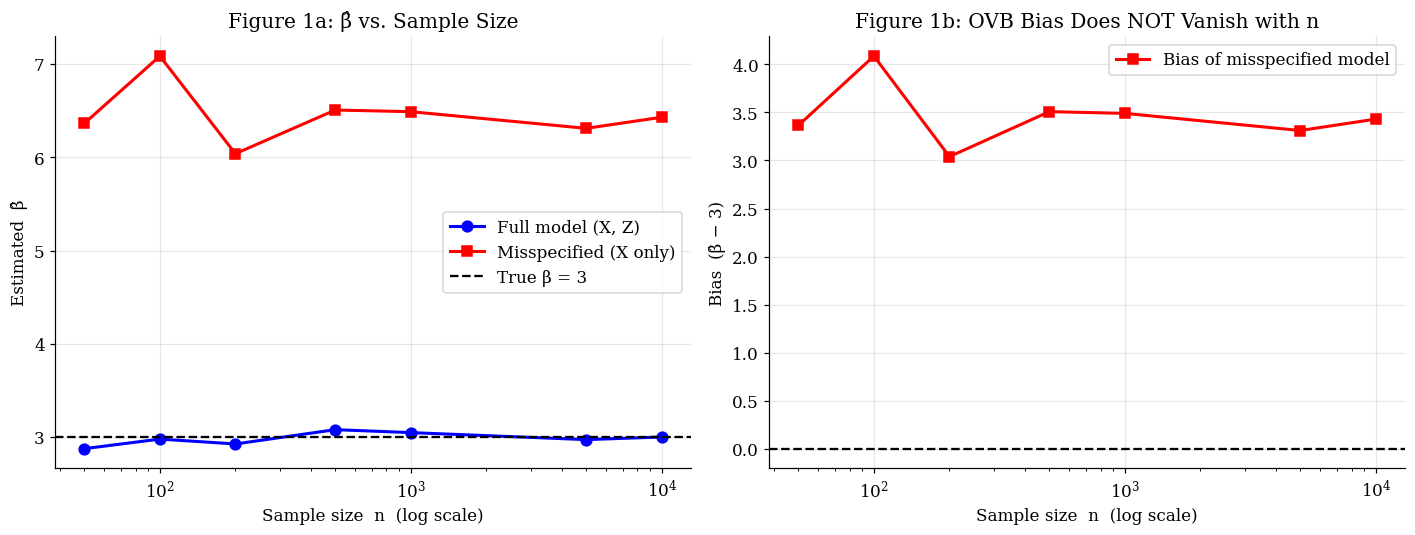

Key finding: the bias persists at ALL sample sizes — OVB is asymptotic, not finite-sample.


In [6]:
# ─── Figure 1: OVB across sample sizes
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.plot(sample_sizes, full_bs, 'bo-', lw=2, ms=7, label='Full model (X, Z)')
ax.plot(sample_sizes, mis_bs,  'rs-', lw=2, ms=7, label='Misspecified (X only)')
ax.axhline(3.0, color='k', ls='--', lw=1.5, label='True β = 3')
ax.set_xscale('log')
ax.set_xlabel('Sample size  n  (log scale)')
ax.set_ylabel('Estimated  β̂')
ax.set_title('Figure 1a: β̂ vs. Sample Size')
ax.legend()
ax.grid(True, alpha=0.3)

ax2 = axes[1]
bias = [m - 3.0 for m in mis_bs]
ax2.plot(sample_sizes, bias, 'rs-', lw=2, ms=7, label='Bias of misspecified model')
ax2.axhline(0, color='k', ls='--', lw=1.5)
ax2.set_xscale('log')
ax2.set_xlabel('Sample size  n  (log scale)')
ax2.set_ylabel('Bias  (β̂ − 3)')
ax2.set_title('Figure 1b: OVB Bias Does NOT Vanish with n')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig1_ovb.png', dpi=150, bbox_inches='tight')
plt.show()
print("Key finding: the bias persists at ALL sample sizes — OVB is asymptotic, not finite-sample.")


---
## Problem 2 – Sensitivity of OLS to Outliers

### Question 2b – Simulation Illustration

In [32]:
# ─── Design: n=100 clean + 3 high-leverage outliers
np.random.seed(42)
n_clean = 100
X_c = np.random.uniform(0, 10, n_clean)
Y_c = 2.0 + 1.5*X_c + np.random.normal(0, 1, n_clean)   # True: α=2, β=1.5

# Outliers at high x with low y  →  downward leverage
X_out = np.append(X_c, [9.5, 9.8, 10.0])
Y_out = np.append(Y_c, [1.0, 0.5, -1.0])

fc = OLS(Y_c, sm.add_constant(X_c)).fit()
fo = OLS(Y_out, sm.add_constant(X_out)).fit()

results_tbl = pd.DataFrame({
    'Model':      ['True DGP', 'OLS – clean data', 'OLS – with outliers'],
    'Intercept':  [2.000, round(fc.params[0],3), round(fo.params[0],3)],
    'Slope':      [1.500, round(fc.params[1],3), round(fo.params[1],3)]
})
print(results_tbl.to_string(index=False))


              Model  Intercept  Slope
           True DGP      2.000  1.500
   OLS – clean data      2.215  1.454
OLS – with outliers      2.968  1.201


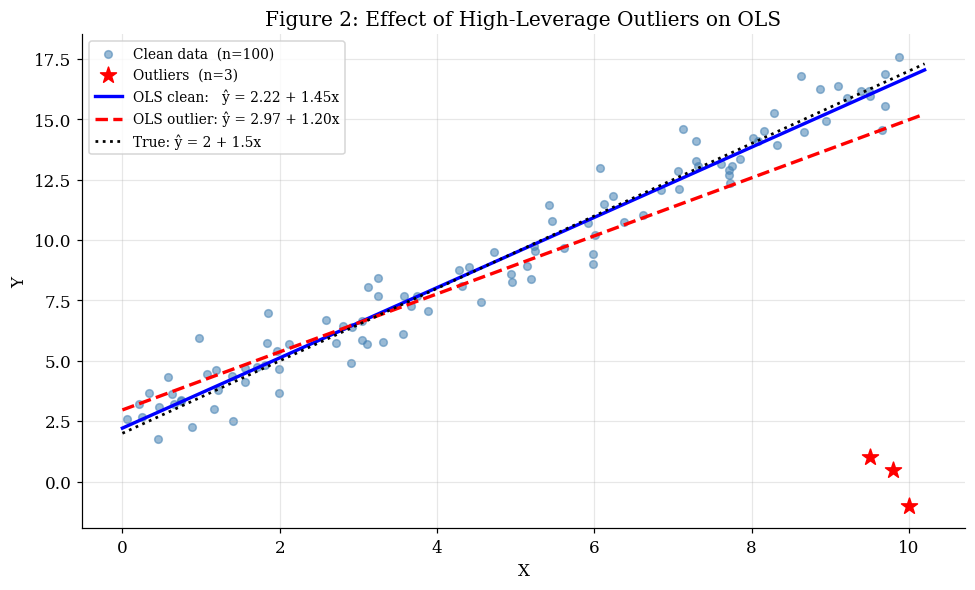

Slope distortion:     -0.253
Intercept distortion: +0.752


In [33]:
# ─── Figure 2
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(X_c, Y_c, color='steelblue', alpha=0.55, s=25, label='Clean data  (n=100)')
ax.scatter([9.5, 9.8, 10.0], [1.0, 0.5, -1.0],
           color='red', s=120, marker='*', zorder=6, label='Outliers  (n=3)')

xr = np.linspace(0, 10.2, 200)
ax.plot(xr, fc.params[0] + fc.params[1]*xr, 'b-',  lw=2.2,
        label=f'OLS clean:   ŷ = {fc.params[0]:.2f} + {fc.params[1]:.2f}x')
ax.plot(xr, fo.params[0] + fo.params[1]*xr, 'r--', lw=2.2,
        label=f'OLS outlier: ŷ = {fo.params[0]:.2f} + {fo.params[1]:.2f}x')
ax.plot(xr, 2 + 1.5*xr, 'k:', lw=1.8, label='True: ŷ = 2 + 1.5x')

ax.set_xlabel('X'); ax.set_ylabel('Y')
ax.set_title('Figure 2: Effect of High-Leverage Outliers on OLS')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig2_outlier.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Slope distortion:     {fo.params[1] - fc.params[1]:+.3f}")
print(f"Intercept distortion: {fo.params[0] - fc.params[0]:+.3f}")


### Question 2c – Proof: β̂ → yₙ/xₙ as xₙ → ∞

**Setup:** $n-1$ points at $(x_i, 0)$ and one outlier $(x_n, y_n)$.  
Sample mean: $\bar{x} = (S_0 + x_n)/n$ where $S_0 = \sum_{i=1}^{n-1} x_i$ (finite).

**Numerator** of OLS slope (only the $n$-th term survives since $y_1=\cdots=y_{n-1}=0$):
$$\sum_i (x_i - \bar{x})(y_i - \bar{y}) = (x_n - \bar{x})y_n$$

**Denominator:** $(x_n - \bar{x})^2 \sim x_n^2(n-1)^2/n^2$ dominates as $x_n \to \infty$.

Therefore:
$$\hat{\beta} = \frac{(x_n - \bar{x})y_n}{(x_n - \bar{x})^2 + \text{(finite)}} \xrightarrow{x_n \to \infty} \frac{y_n}{x_n} \quad \blacksquare$$


In [34]:
# ─── Numerical verification of the 2c proof
n_pts = 20
x_base = np.random.uniform(0, 5, n_pts - 1)
y_base = np.zeros(n_pts - 1)
yn = 50.0   # fixed outlier y-value

x_n_values = [10, 50, 100, 500, 1000, 5000, 10000]
rows = []
for xn in x_n_values:
    Xv = np.append(x_base, xn)
    Yv = np.append(y_base, yn)
    slope = OLS(Yv, sm.add_constant(Xv)).fit().params[1]
    rows.append({'xₙ': xn, 'β̂': round(slope, 6), 'yₙ/xₙ': round(yn/xn, 6), 'Ratio β̂/(yₙ/xₙ)': round(slope/(yn/xn), 4)})

print(pd.DataFrame(rows).to_string(index=False))
print("\nAs xₙ → ∞,  β̂ converges to yₙ/xₙ regardless of the other n−1 points.")


   xₙ       β̂  yₙ/xₙ  Ratio β̂/(yₙ/xₙ)
   10 3.465003  5.000            0.6930
   50 1.036538  1.000            1.0365
  100 0.511933  0.500            1.0239
  500 0.100555  0.100            1.0056
 1000 0.050141  0.050            1.0028
 5000 0.010006  0.010            1.0006
10000 0.005001  0.005            1.0003

As xₙ → ∞,  β̂ converges to yₙ/xₙ regardless of the other n−1 points.


---
## Problem 3 – Model Selection
### Dataset: FE-GWP1_model_selection_1.csv  (Odd Group)

We perform model selection for $Y \sim f(X1, X2, X3, X4, X5)$ using:
1. **Forward Stepwise Selection (BIC)**
2. **Backward Stepwise Selection (BIC)**
3. **All-Subsets comparison (AIC and Adjusted R²)**


In [21]:
# ─── Load real dataset
import os
# Try upload path first, fallback to working directory
data_path = 'FE-GWP1_model_selection_1.csv'
df = pd.read_csv(data_path)
print(f"Shape: {df.shape}")
print("\nFirst 5 rows:")
display(df.head())
print("\nDescriptive statistics:")
display(df.describe().round(4))


Shape: (100, 6)

First 5 rows:


,Y,X1,X2,X3,X4,X5
0,3.388410,0.017954,-0.800583,-0.352454,2.187210,1.014887
1,0.287191,0.083057,-0.597947,-0.357639,-1.630284,0.221841
2,3.989645,-0.923437,-1.386575,1.180202,0.632606,-1.576638
3,-2.959602,-0.313775,2.955133,-1.798692,-2.117621,0.159291
4,0.529773,0.388996,1.019611,0.472062,0.590497,0.877048



Descriptive statistics:


,Y,X1,X2,X3,X4,X5
count,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000
mean,1.2574,0.0268,0.0846,-0.0160,0.1224,-0.2017
std,1.4367,0.4817,0.9621,0.9766,1.0769,1.0734
min,-2.9596,-1.2752,-2.0420,-2.2285,-2.6973,-3.5264
25%,0.3495,-0.3166,-0.6770,-0.5729,-0.4310,-0.9602
50%,1.2785,0.0402,0.0404,0.0569,0.2796,-0.1858
75%,2.1530,0.3739,0.7482,0.6364,0.7479,0.5066
max,5.1768,1.0831,2.9551,1.8168,3.1673,2.4998


In [22]:
# ─── Fit all 31 subsets, collect AIC / BIC / Adj-R²
pred_names = ['X1','X2','X3','X4','X5']

def fit_subset(df, preds):
    Xmat = sm.add_constant(df[preds])
    m = OLS(df['Y'], Xmat).fit()
    return {'preds': list(preds), 'k': len(preds),
            'AIC': m.aic, 'BIC': m.bic, 'AdjR2': m.rsquared_adj,
            'R2':  m.rsquared}

all_fits = [fit_subset(df, list(c))
            for k in range(1, 6)
            for c in combinations(pred_names, k)]

df_fits = pd.DataFrame(all_fits).sort_values('BIC').reset_index(drop=True)
print("Top 8 models by BIC:")
print(df_fits[['preds','k','AIC','BIC','AdjR2','R2']].head(8).to_string(index=False))


Top 8 models by BIC:
               preds  k        AIC        BIC    AdjR2       R2
    [X2, X3, X4, X5]  4 260.616684 273.642535 0.633974 0.648763
        [X2, X3, X4]  3 264.291054 274.711735 0.616639 0.628256
[X1, X2, X3, X4, X5]  5 262.592528 278.223549 0.630170 0.648848
    [X1, X2, X3, X4]  4 266.191097 279.216948 0.612991 0.628628
        [X2, X4, X5]  3 291.889597 302.310277 0.494796 0.510106
            [X3, X4]  2 296.442510 304.258021 0.466143 0.476928
        [X3, X4, X5]  3 294.842233 305.262914 0.479657 0.495425
            [X2, X4]  2 299.002018 306.817529 0.452303 0.463367


In [23]:
# ─── Forward Stepwise Selection (BIC)
remaining = pred_names.copy()
selected  = []
current_bic = np.inf
print("Forward Stepwise Selection (BIC)\n" + "─"*55)
for step in range(1, 6):
    bics = {p: fit_subset(df, selected + [p])['BIC'] for p in remaining}
    best_p = min(bics, key=bics.get)
    if bics[best_p] < current_bic:
        current_bic = bics[best_p]
        selected.append(best_p)
        remaining.remove(best_p)
        print(f"  Step {step}: add '{best_p}'  →  BIC = {current_bic:.4f}  |  model = {selected}")
    else:
        print(f"  Step {step}: adding '{best_p}' gives BIC = {bics[best_p]:.4f} — no improvement. STOP.")
        break
print(f"\nForward BIC final model: {selected}")


Forward Stepwise Selection (BIC)
───────────────────────────────────────────────────────
  Step 1: add 'X4'  →  BIC = 330.2390  |  model = ['X4']
  Step 2: add 'X3'  →  BIC = 304.2580  |  model = ['X4', 'X3']
  Step 3: add 'X2'  →  BIC = 274.7117  |  model = ['X4', 'X3', 'X2']
  Step 4: add 'X5'  →  BIC = 273.6425  |  model = ['X4', 'X3', 'X2', 'X5']
  Step 5: adding 'X1' gives BIC = 278.2235 — no improvement. STOP.

Forward BIC final model: ['X4', 'X3', 'X2', 'X5']


In [24]:
# ─── Backward Stepwise Selection (BIC)
selected_b   = pred_names.copy()
current_bic_b = fit_subset(df, selected_b)['BIC']
print("Backward Stepwise Selection (BIC)\n" + "─"*55)
print(f"  Start: {selected_b}   BIC = {current_bic_b:.4f}")
for step in range(1, 6):
    if len(selected_b) == 1:
        break
    bics = {p: fit_subset(df, [x for x in selected_b if x != p])['BIC']
            for p in selected_b}
    best_drop = min(bics, key=bics.get)
    if bics[best_drop] < current_bic_b:
        current_bic_b = bics[best_drop]
        selected_b.remove(best_drop)
        print(f"  Step {step}: drop '{best_drop}'  →  BIC = {current_bic_b:.4f}  |  model = {selected_b}")
    else:
        print(f"  Step {step}: no improvement. STOP.")
        break
print(f"\nBackward BIC final model: {selected_b}")


Backward Stepwise Selection (BIC)
───────────────────────────────────────────────────────
  Start: ['X1', 'X2', 'X3', 'X4', 'X5']   BIC = 278.2235
  Step 1: drop 'X1'  →  BIC = 273.6425  |  model = ['X2', 'X3', 'X4', 'X5']
  Step 2: no improvement. STOP.

Backward BIC final model: ['X2', 'X3', 'X4', 'X5']


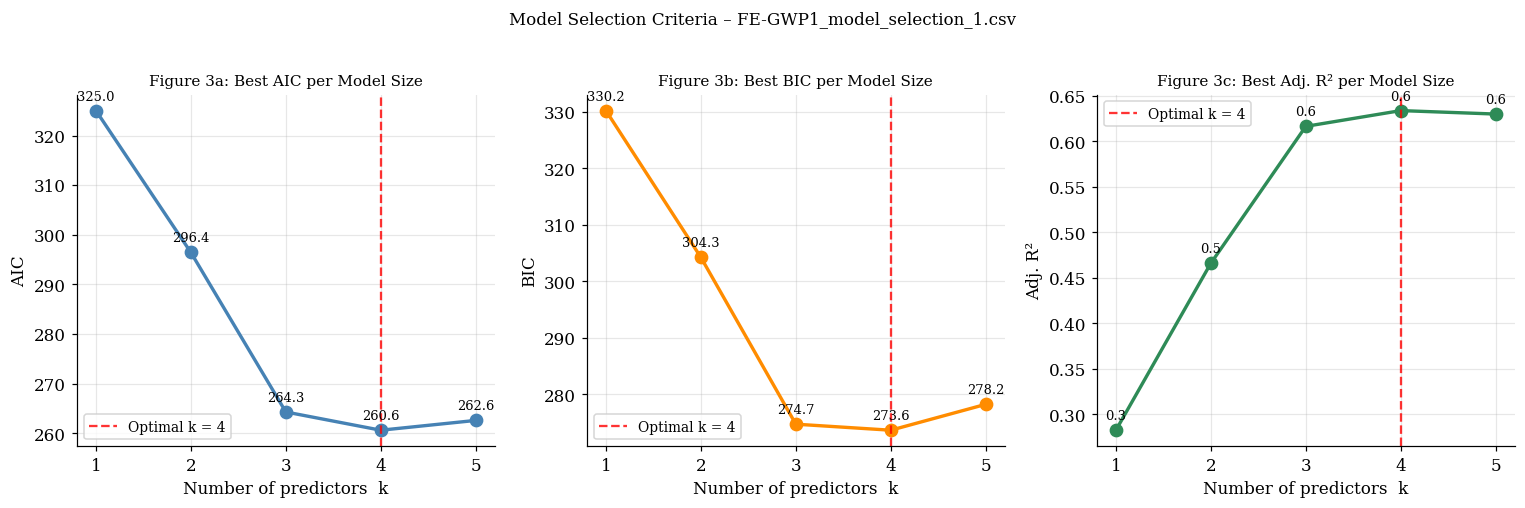

All three criteria select k = 4: {X2, X3, X4, X5}. X1 is excluded.


In [25]:
# ─── Figure: criterion curves across model sizes
best_aic_k = df_fits.groupby('k')['AIC'].min()
best_bic_k = df_fits.groupby('k')['BIC'].min()
best_r2_k  = df_fits.groupby('k')['AdjR2'].max()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
specs = [
    (best_aic_k, 'AIC',    'steelblue',  'Figure 3a: Best AIC per Model Size'),
    (best_bic_k, 'BIC',    'darkorange', 'Figure 3b: Best BIC per Model Size'),
    (best_r2_k,  'Adj. R²','seagreen',   'Figure 3c: Best Adj. R² per Model Size'),
]
for ax, (vals, ylabel, color, title) in zip(axes, specs):
    ax.plot(vals.index, vals.values, 'o-', color=color, lw=2.2, ms=8)
    best_k = vals.idxmax() if ylabel == 'Adj. R²' else vals.idxmin()
    ax.axvline(best_k, color='red', ls='--', lw=1.5, alpha=0.8, label=f'Optimal k = {best_k}')
    for xi, yi in zip(vals.index, vals.values):
        ax.annotate(f'{yi:.1f}', (xi, yi), textcoords='offset points',
                    xytext=(0, 7), ha='center', fontsize=8.5)
    ax.set_xlabel('Number of predictors  k')
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=10)
    ax.set_xticks(range(1, 6))
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
plt.suptitle('Model Selection Criteria – FE-GWP1_model_selection_1.csv', fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig('fig_q3_criteria.png', dpi=150, bbox_inches='tight')
plt.show()
print("All three criteria select k = 4: {X2, X3, X4, X5}. X1 is excluded.")


In [26]:
# ─── Final model OLS summary
final_preds = ['X2','X3','X4','X5']
Xf = sm.add_constant(df[final_preds])
mf = OLS(df['Y'], Xf).fit()
print(mf.summary())


                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.649
Model:                            OLS   Adj. R-squared:                  0.634
Method:                 Least Squares   F-statistic:                     43.87
Date:                Tue, 30 Jun 2026   Prob (F-statistic):           8.29e-21
Time:                        17:53:56   Log-Likelihood:                -125.31
No. Observations:                 100   AIC:                             260.6
Df Residuals:                      95   BIC:                             273.6
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.1893      0.089     13.333      0.0

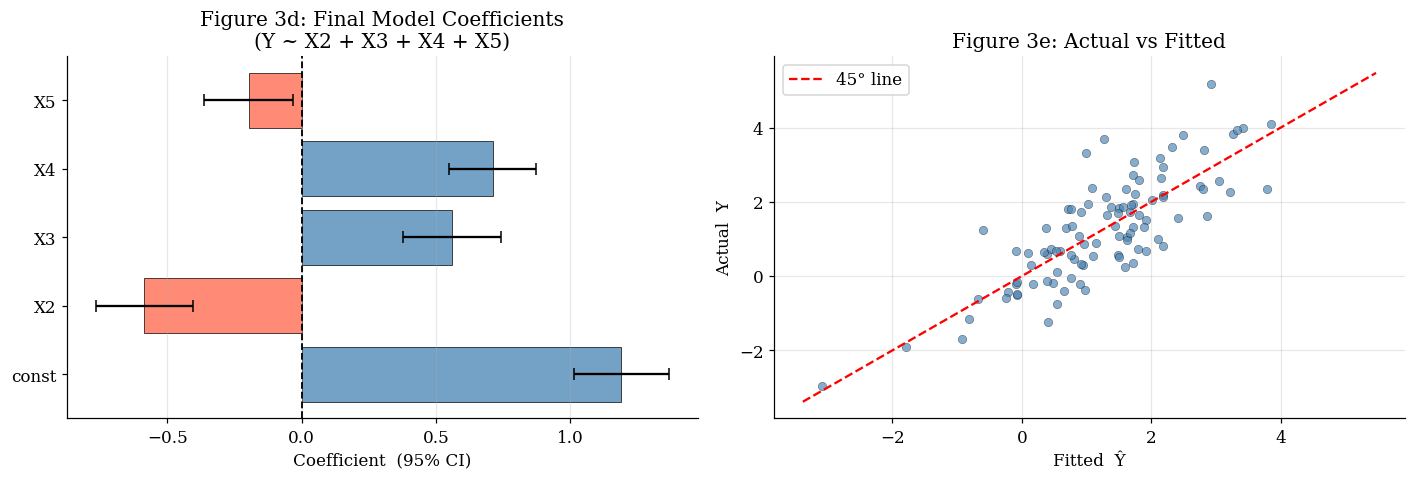

In [27]:
# ─── Coefficient plot with 95% CI
coef_names = list(mf.params.index)
coefs  = np.array(mf.params)
ci     = np.array(mf.conf_int())
err_lo = coefs - ci[:, 0]
err_hi = ci[:, 1] - coefs

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
colors = ['steelblue' if c > 0 else 'tomato' for c in coefs]
ax.barh(coef_names, coefs, xerr=np.array([err_lo, err_hi]),
        color=colors, alpha=0.75, edgecolor='black', lw=0.6, capsize=4)
ax.axvline(0, color='black', lw=1.2, ls='--')
ax.set_xlabel('Coefficient  (95% CI)')
ax.set_title('Figure 3d: Final Model Coefficients\n(Y ~ X2 + X3 + X4 + X5)')
ax.grid(True, axis='x', alpha=0.3)

# Actual vs fitted
ax2 = axes[1]
y_hat = np.array(mf.fittedvalues)
Y_arr = np.array(df['Y'])
ax2.scatter(y_hat, Y_arr, color='steelblue', alpha=0.65, s=30, edgecolors='k', lw=0.3)
lims = [min(y_hat.min(), Y_arr.min())-0.3, max(y_hat.max(), Y_arr.max())+0.3]
ax2.plot(lims, lims, 'r--', lw=1.5, label='45° line')
ax2.set_xlabel('Fitted  Ŷ'); ax2.set_ylabel('Actual  Y')
ax2.set_title('Figure 3e: Actual vs Fitted')
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig_q3_fit.png', dpi=150, bbox_inches='tight')
plt.show()


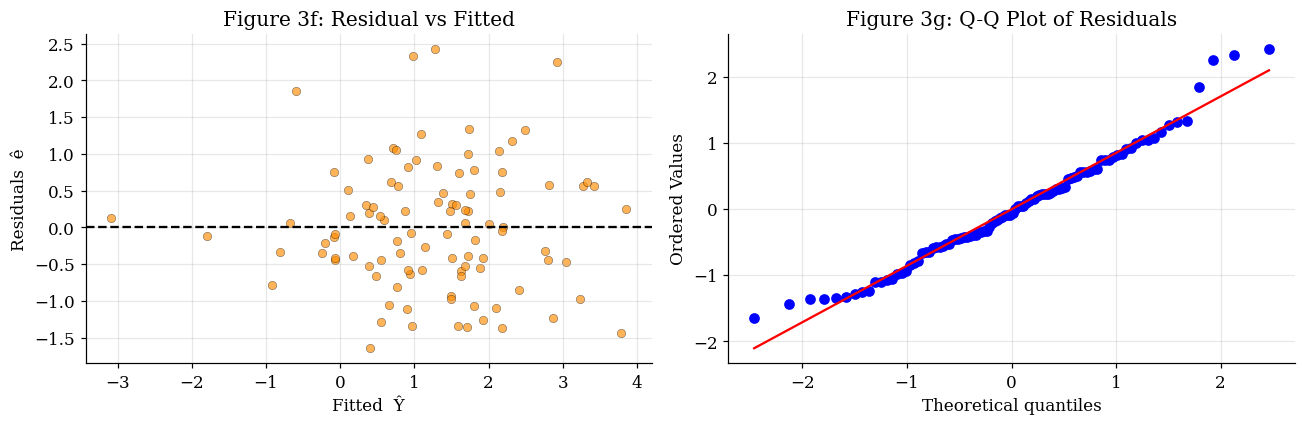

Jarque-Bera normality test: stat = 3.9202, p = 0.1408
Residuals appear normally distributed.

Final model summary: R² = 0.6488, Adj-R² = 0.6340
AIC = 260.6167, BIC = 273.6425


In [28]:
# ─── Residual diagnostics
resid = np.array(mf.resid)
y_hat = np.array(mf.fittedvalues)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_hat, resid, color='darkorange', alpha=0.65, s=30, edgecolors='k', lw=0.3)
axes[0].axhline(0, color='black', lw=1.5, ls='--')
axes[0].set_xlabel('Fitted  Ŷ'); axes[0].set_ylabel('Residuals  ê')
axes[0].set_title('Figure 3f: Residual vs Fitted')
axes[0].grid(True, alpha=0.3)

from scipy import stats as scistats
scistats.probplot(resid, dist="norm", plot=axes[1])
axes[1].set_title('Figure 3g: Q-Q Plot of Residuals')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig_q3_diagnostics.png', dpi=150, bbox_inches='tight')
plt.show()

# Jarque-Bera normality test
jb_stat, jb_p = scistats.jarque_bera(resid)
print(f"Jarque-Bera normality test: stat = {jb_stat:.4f}, p = {jb_p:.4f}")
print("Residuals appear normally distributed." if jb_p > 0.05 else "Evidence against normality.")
print(f"\nFinal model summary: R² = {mf.rsquared:.4f}, Adj-R² = {mf.rsquared_adj:.4f}")
print(f"AIC = {mf.aic:.4f}, BIC = {mf.bic:.4f}")


### Question 3b – BIC vs. AIC: Which is More Reliable?

**BIC is the more reliable (consistent) criterion** (Schwarz, 1978).

**Proof using the hint** — let $M_0$: $y = \alpha + \beta x + \varepsilon$ (true) and $M_1$: $y = \alpha + \beta x + \gamma z + \mu$ (over-fitted):

- **AIC:** $\text{AIC}(M_1) - \text{AIC}(M_0) = -2[\ell(M_1) - \ell(M_0)] + 2$. The log-likelihood gain from adding irrelevant $z$ converges to $\chi^2(1)/2$, with $E[\chi^2(1)] = 1$, so AIC's expected gain is zero. AIC has no asymptotic pressure to exclude $z$ → **over-selects with positive probability forever**.

- **BIC:** $\text{BIC}(M_1) - \text{BIC}(M_0) = -2[\ell(M_1) - \ell(M_0)] + \ln n$. Since $\ln n \to \infty$, the penalty eventually dominates any finite likelihood gain → $P(\text{BIC selects } M_0) \to 1$ as $n \to \infty$.

**Verdict:** BIC is *consistent*; AIC is not. Use BIC for structural model identification; AIC for prediction-focused work.


---
## References

Barnett, V., & Lewis, T. (1994). *Outliers in Statistical Data* (3rd ed.). John Wiley & Sons.

Cook, R. D. (1977). Detection of influential observations in linear regression. *Technometrics, 19*(1), 15–18.

Huber, P. J. (1964). Robust estimation of a location parameter. *The Annals of Mathematical Statistics, 35*(1), 73–101.

Johansen, S. (1991). Estimation and hypothesis testing of cointegration vectors in Gaussian vector autoregressive models. *Econometrica, 59*(6), 1551–1580.

Rousseeuw, P. J., & Leroy, A. M. (1987). *Robust Regression and Outlier Detection*. John Wiley & Sons.

Schwarz, G. (1978). Estimating the dimension of a model. *The Annals of Statistics, 6*(2), 461–464.

Wooldridge, J. M. (2020). *Introductory Econometrics: A Modern Approach* (7th ed.). Cengage Learning.
